INTRODUCTION:

We are going to be training makemore - https://github.com/karpathy/makemore - from karpathy. This is trained on approx. 32k names. You input a name, a similar sounding name comes out the other end.

Makemore: Character level language model. In a single word - have a sequence of characters... Character level models model the sequence of characters in words - in this case names - and can predict the next character in the name...

In [14]:
words = open("names.txt", "r").read().splitlines() # Get all of the words as a python array of strings
print(words[:10]) # Print the first 10

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


In [15]:
# Find minimum and max length of words:
import numpy as np

lens = np.array([len(word) for word in words])

max = np.argmax(lens)
min = np.argmin(lens)

print("MAX (",lens[max],"):", words[max], "MIN (",lens[min],"):", words[min])

MAX ( 15 ): muhammadibrahim MIN ( 2 ): an


Predict next char in sequence given prior knowledge of characters from before it... Each word/example like "ava" are built on similar language structure priors - like "a is often followed by v", "a is likely to begin a name", "v is likely followed by a" and "after 'ava' the word is likely to end...".

In a Bigram language model - we only work with 2 characters at a time... So use the previous character to predict the next character in the sequence... Very local. Very simple. Very weak.

BIGRAM MODELS:
- Simply count how often each pairing of characters show up in names...

In [45]:
bigrams = {} # Define bigram dictionary

for word in words:
    # Create an array characters (chrs) - Including the starting and ending markers for the word...
    chrs = ["<S>"] + list(word) + ["<E>"]
    #print(chrs)
    for index in range(0, len(chrs)-1):
        # Get the character pairs in each word...
        ch1, ch2 = chrs[index], chrs[index+1]
        bigram = (ch1, ch2)
        # Look up bigram in the bigrams dictionary - if it doesnt exist then create a new entry with defult of 0 (+1)
        bigrams[bigram] = bigrams.get(bigram, 0) + 1

        # Notice how we get pairs: [<S>, e] & [a, <E>] - hence we can train the bigram model to see e and a to be common starting and finishing characters - if there is enough exampeles of this actually being the case...

print(bigrams)

{('<S>', 'e'): 1531, ('e', 'm'): 769, ('m', 'm'): 168, ('m', 'a'): 2590, ('a', '<E>'): 6640, ('<S>', 'o'): 394, ('o', 'l'): 619, ('l', 'i'): 2480, ('i', 'v'): 269, ('v', 'i'): 911, ('i', 'a'): 2445, ('<S>', 'a'): 4410, ('a', 'v'): 834, ('v', 'a'): 642, ('<S>', 'i'): 591, ('i', 's'): 1316, ('s', 'a'): 1201, ('a', 'b'): 541, ('b', 'e'): 655, ('e', 'l'): 3248, ('l', 'l'): 1345, ('l', 'a'): 2623, ('<S>', 's'): 2055, ('s', 'o'): 531, ('o', 'p'): 95, ('p', 'h'): 204, ('h', 'i'): 729, ('<S>', 'c'): 1542, ('c', 'h'): 664, ('h', 'a'): 2244, ('a', 'r'): 3264, ('r', 'l'): 413, ('l', 'o'): 692, ('o', 't'): 118, ('t', 't'): 374, ('t', 'e'): 716, ('e', '<E>'): 3983, ('<S>', 'm'): 2538, ('m', 'i'): 1256, ('a', 'm'): 1634, ('m', 'e'): 818, ('<S>', 'h'): 874, ('r', 'p'): 14, ('p', 'e'): 197, ('e', 'r'): 1958, ('r', '<E>'): 1377, ('e', 'v'): 463, ('v', 'e'): 568, ('l', 'y'): 1588, ('y', 'n'): 1826, ('n', '<E>'): 6763, ('b', 'i'): 217, ('i', 'g'): 428, ('g', 'a'): 330, ('a', 'i'): 1650, ('i', 'l'): 1345,

In [35]:
# Convert the bigrams to a tuple form - then sort it... 
# Never seen this syntax before... Bit strange - but probs quite efficient...
sorted(bigrams.items(), key=lambda kv: -kv[1]) # we are sorting by the kv[1] i.e the number of occurances...

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [ ]:
# Better to store in a 2D array rather than a dictionary or tuple...

# Here we use pyTorch... Looks very similar to numpy...
import torch

# Define empty array of zeros (use 32 bit int)
example = torch.zeros((3,5), dtype=torch.int32)
print(example)

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


We store the above data as a matrix with each column and row being a respective letter (26) plus the <S> and <E> terms as well... Hence a 28x28 matrix... It isnt a reflection as character order matters here... Like a,e counts and e,a counts are not intermingled...

In [47]:
# Define torch array
N = torch.zeros((28, 28), dtype=torch.int32)

# Define a character index from a to z...

# Concatinate all words in the dataset together with no spaces inbetween
concat_all_words = "".join(words)
print(concat_all_words)

# Use the set operator to only draw out the set of characters which make up the concatinated string... (i.e only bring out the single letters in the concat_all_words - ignoring repeats)
seperate_chars = set(concat_all_words) 
print(seperate_chars)

# Move the seperate_chars (26 of them) into a list (array) and then sort them - from a to z
sorted_chars_list = sorted(list(seperate_chars))
print(sorted_chars_list)

# Hence we create index from a-z for 0-25...
stoi = {s:i for i,s in enumerate(sorted_chars_list)}
stoi["<S>"] = 26
stoi["<E>"] = 27
print(stoi)


...
{'u', 'x', 'r', 'y', 'c', 'g', 'f', 'q', 'e', 'w', 'j', 'o', 's', 'd', 'p', 'v', 'b', 't', 'a', 'h', 'k', 'z', 'n', 'l', 'i', 'm'}
['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
{'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4, 'f': 5, 'g': 6, 'h': 7, 'i': 8, 'j': 9, 'k': 10, 'l': 11, 'm': 12, 'n': 13, 'o': 14, 'p': 15, 'q': 16, 'r': 17, 's': 18, 't': 19, 'u': 20, 'v': 21, 'w': 22, 'x': 23, 'y': 24, 'z': 25, '<S>': 26, '<E>': 27}


In [ ]:
# Now instead of iterating through for words and storing characters - we store just the character index...
# Then store these in the 28x28 array

for word in words:
    # Create an array characters (chrs) - Including the starting and ending markers for the word...
    chrs = ["<S>"] + list(word) + ["<E>"]
    
    for index in range(0, len(chrs)-1):
        # Get the character pairs in each word...
        ch1, ch2 = chrs[index], chrs[index+1]
        N[stoi[ch1], stoi[ch2]] += 1

print(N) # Here we have the matricies of frequencies for order-dependant character pairings...

tensor([[ 556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568, 2528,
         1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,  182,
         2050,  435,    0, 6640],
        [ 321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,  103,
            0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,    0,
           83,    0,    0,  114],
        [ 815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,  116,
            0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,    3,
          104,    4,    0,   97],
        [1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,   60,
           30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,    0,
          317,    1,    0,  516],
        [ 679,  121,  153,  384, 1271,   82,  125,  152,  818,   55,  178, 3248,
          769, 2675,  269,   83,   14, 1958,  861,  580,   69,  463,   50,  132,
         1070,  181,    0, 3983],
        [ 242,    0,

NOTE: The rows is given by the first character & the cols are given by the second character

Hence "a", "e" is stored as N[0, 4]

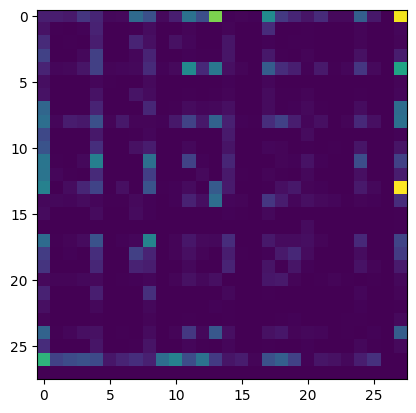

In [ ]:
# Plot the matrix...
import matplotlib.pyplot as plt

plt.imshow(N) # NOTE: 28x28 array image...

In [ ]:
# CODE FROM KARPATHY FOR THE ARRAY:

https://www.youtube.com/watch?v=PaCmpygFfXo&list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&index=3 [19 mins...]